\begin{center}
{\LARGE \textbf{EN3160 Image Processing and Machine Vision}}\\[0.5em]
{\Large Assignment 3 -- Neural Networks}\\[1.5em]

\textbf{Name:} S.A.D. Priyadarshana\\[0.3em]
\textbf{Index:} 230502X\\[0.3em]
\textbf{GitHub:} \href{https://github.com/denethp/CV-Assignment-03}{denethp/CV-Assignment-03}
\end{center}

\vspace{1em}

$\underline{\textbf{Question 1}}$

In [6]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

%matplotlib inline

_ = torch.manual_seed(0)  # fixed seed so my runs are reproducible

In [7]:
# CIFAR-10, normalized to [-1, 1]
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

In [8]:
def accuracy(loader, forward):
    # Percentage of correctly classified images in a loader
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            predicted = torch.argmax(forward(x), dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

$\textbf{Baseline: single dense layer with MSE loss}$

Before making the required changes, I first trained the given network as it is, so I have a reference to compare
against. It maps the flattened image ($3 \times 32 \times 32 = 3072$ values) straight to the 10 class scores
with a single weight matrix and is trained with a mean-squared-error loss.

In [10]:
Din = 3 * 32 * 32  # flattened CIFAR-10 image
K = 10             # number of classes
std = 1e-5

w = torch.randn(Din, K) * std
b = torch.zeros(K)

iterations = 20
lr = 2e-6
lr_decay = 0.9
reg = 0
loss_history = []

for t in range(iterations):
    running_loss = 0.0
    for inputs, labels in trainloader:
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_pred = x_train.mm(w) + b

        # MSE loss with L2 regularization
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) + reg * torch.sum(w ** 2)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        w -= lr * dw
        b -= lr * db

    print(f'Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader):.4f}')
    lr *= lr_decay

Epoch 1/20, Loss: 0.9770
Epoch 2/20, Loss: 0.9499
Epoch 3/20, Loss: 0.9361
Epoch 4/20, Loss: 0.9275
Epoch 5/20, Loss: 0.9216
Epoch 6/20, Loss: 0.9172
Epoch 7/20, Loss: 0.9138
Epoch 8/20, Loss: 0.9111
Epoch 9/20, Loss: 0.9088
Epoch 10/20, Loss: 0.9070
Epoch 11/20, Loss: 0.9054
Epoch 12/20, Loss: 0.9041
Epoch 13/20, Loss: 0.9029
Epoch 14/20, Loss: 0.9020
Epoch 15/20, Loss: 0.9011
Epoch 16/20, Loss: 0.9004
Epoch 17/20, Loss: 0.8997
Epoch 18/20, Loss: 0.8991
Epoch 19/20, Loss: 0.8986
Epoch 20/20, Loss: 0.8982


Training accuracy: 32.23%
Test accuracy: 32.43%


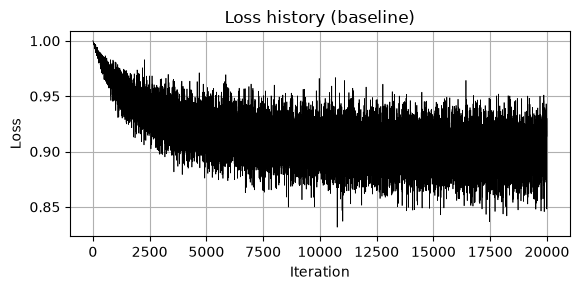

In [11]:
baseline_train_acc = accuracy(trainloader, lambda x: x.mm(w) + b)
baseline_test_acc = accuracy(testloader, lambda x: x.mm(w) + b)
print(f'Training accuracy: {baseline_train_acc:.2f}%')
print(f'Test accuracy: {baseline_test_acc:.2f}%')

plt.figure(figsize=(6, 3))
plt.plot(loss_history, color='k', linewidth=0.5)
plt.title('Loss history (baseline)')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.tight_layout()
plt.show()

$\textbf{(a) Adding a middle layer with 100 nodes and sigmoid activation}$

I added a hidden layer of $H = 100$ nodes between the input and the output, so the network becomes

$$\mathbf{h} = \sigma(\mathbf{x} W_1 + \mathbf{b}_1), \qquad \hat{\mathbf{y}} = \mathbf{h} W_2 + \mathbf{b}_2,$$

with $W_1 \in \mathbb{R}^{3072 \times 100}$ and $W_2 \in \mathbb{R}^{100 \times 10}$. I still compute the forward pass and the
gradients by hand. Going backwards from the output gradient $\partial L / \partial \hat{\mathbf{y}}$:

$$\frac{\partial L}{\partial W_2} = \mathbf{h}^T \frac{\partial L}{\partial \hat{\mathbf{y}}}, \qquad
\frac{\partial L}{\partial \mathbf{z}_1} = \Big(\frac{\partial L}{\partial \hat{\mathbf{y}}} W_2^T\Big) \odot \mathbf{h} \odot (1 - \mathbf{h}), \qquad
\frac{\partial L}{\partial W_1} = \mathbf{x}^T \frac{\partial L}{\partial \mathbf{z}_1},$$

where $\mathbf{h} \odot (1 - \mathbf{h})$ is the derivative of the sigmoid. I verified these gradients against numerical
(finite-difference) gradients before training.

The tiny initialization ($10^{-5}$) of the single-layer network does not work with a hidden layer, because every
hidden node would output $\sigma(0) = 0.5$ and the signal would barely reach the output. So I initialized each weight
matrix with standard deviation $1/\sqrt{\text{fan-in}}$. To speed up training, I loaded the whole dataset onto the GPU
once and drew the mini-batches from it directly.

In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def to_device_tensors(dataset):
    # Same preprocessing as the transform above: [0, 1] -> [-1, 1], then flatten (C, H, W)
    x = torch.tensor(dataset.data, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    x = ((x - 0.5) / 0.5).reshape(len(dataset), -1)
    y = torch.tensor(dataset.targets)
    return x.to(device), y.to(device)

X_train, Y_train = to_device_tensors(trainset)
X_test, Y_test = to_device_tensors(testset)
print('Train:', tuple(X_train.shape), ' Test:', tuple(X_test.shape))

Device: cuda
Train: (50000, 3072)  Test: (10000, 3072)


In [13]:
Din = 3 * 32 * 32
H = 100  # hidden nodes
K = 10

def init_params(seed=0):
    g = torch.Generator(device=device).manual_seed(seed)
    w1 = torch.randn(Din, H, device=device, generator=g) / Din ** 0.5
    b1 = torch.zeros(H, device=device)
    w2 = torch.randn(H, K, device=device, generator=g) / H ** 0.5
    b2 = torch.zeros(K, device=device)
    return [w1, b1, w2, b2]

def forward(x, params):
    w1, b1, w2, b2 = params
    h = torch.sigmoid(x.mm(w1) + b1)  # hidden layer
    y_pred = h.mm(w2) + b2            # output scores
    return y_pred, h

def evaluate(X, Y, params):
    with torch.no_grad():
        predicted = torch.argmax(forward(X, params)[0], dim=1)
    return 100 * (predicted == Y).float().mean().item()

def train(loss_fn, epochs=10, lr=0.05, lr_decay=0.9, reg=0.0, seed=0):
    # Mini-batch gradient descent with manually computed gradients
    params = init_params(seed)
    w1, b1, w2, b2 = params
    g = torch.Generator(device=device).manual_seed(seed)
    N = X_train.shape[0]
    loss_history, epoch_loss = [], []

    for epoch in range(epochs):
        perm = torch.randperm(N, device=device, generator=g)
        running_loss = 0.0
        for i in range(0, N, batch_size):
            idx = perm[i:i + batch_size]
            x = X_train[idx]
            y_onehot = nn.functional.one_hot(Y_train[idx], K).float()

            # Forward pass
            y_pred, h = forward(x, params)
            loss, dy_pred = loss_fn(y_pred, y_onehot)
            loss = loss + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))

            # Backpropagation
            dw2 = h.t().mm(dy_pred) + 2 * reg * w2
            db2 = dy_pred.sum(dim=0)
            dz1 = dy_pred.mm(w2.t()) * h * (1 - h)  # through the sigmoid
            dw1 = x.t().mm(dz1) + 2 * reg * w1
            db1 = dz1.sum(dim=0)

            # Parameter update
            w1 -= lr * dw1
            b1 -= lr * db1
            w2 -= lr * dw2
            b2 -= lr * db2

            loss_history.append(loss.item())
            running_loss += loss.item()

        epoch_loss.append(running_loss / (N // batch_size))
        print(f'Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss[-1]:.4f}')
        lr *= lr_decay

    return params, loss_history, epoch_loss

To see the effect of the hidden layer on its own, I first trained it with the same MSE loss as the baseline, for 10 epochs.

In [14]:
def mse_loss(y_pred, y_onehot):
    n = y_pred.shape[0]
    loss = torch.sum((y_pred - y_onehot) ** 2) / n
    dy_pred = 2.0 * (y_pred - y_onehot) / n
    return loss, dy_pred

params_mse, loss_history_mse, epoch_loss_mse = train(mse_loss, epochs=10, lr=0.05)

mse_train_acc = evaluate(X_train, Y_train, params_mse)
mse_test_acc = evaluate(X_test, Y_test, params_mse)
print(f'Training accuracy: {mse_train_acc:.2f}%')
print(f'Test accuracy: {mse_test_acc:.2f}%')

Epoch 1/10, Loss: 2.0829
Epoch 2/10, Loss: 0.8287
Epoch 3/10, Loss: 0.7952
Epoch 4/10, Loss: 0.7732
Epoch 5/10, Loss: 0.7589
Epoch 6/10, Loss: 0.7472
Epoch 7/10, Loss: 0.7385
Epoch 8/10, Loss: 0.7321
Epoch 9/10, Loss: 0.7258
Epoch 10/10, Loss: 0.7208
Training accuracy: 47.71%
Test accuracy: 44.01%


$\textbf{(b) Using the cross-entropy loss}$

Next, I replaced the MSE loss with the cross-entropy loss. The output scores $\hat{\mathbf{y}}$ are first turned into class
probabilities with the softmax function, and the loss is the average negative log-probability of the correct class:

$$p_k = \frac{e^{\hat{y}_k}}{\sum_{j=1}^{K} e^{\hat{y}_j}}, \qquad L = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{K} y_{ik} \log p_{ik}.$$

The gradient of this loss with respect to the output scores simplifies to

$$\frac{\partial L}{\partial \hat{\mathbf{y}}} = \frac{1}{N}(\mathbf{p} - \mathbf{y}),$$

so only the output gradient changes, and the rest of my backpropagation through the hidden layer stays the same. I
computed the softmax through `log_softmax`, which subtracts the largest score first, so that large scores cannot
overflow the exponential. I also checked this gradient numerically, and kept every other setting identical to the
MSE run (10 epochs, learning rate 0.05, decay 0.9) so that the two losses can be compared fairly.

In [15]:
def cross_entropy_loss(y_pred, y_onehot):
    n = y_pred.shape[0]
    log_p = torch.log_softmax(y_pred, dim=1)  # numerically stable log-softmax
    loss = -torch.sum(y_onehot * log_p) / n
    dy_pred = (torch.exp(log_p) - y_onehot) / n
    return loss, dy_pred

params_ce, loss_history_ce, epoch_loss_ce = train(cross_entropy_loss, epochs=10, lr=0.05)

ce_train_acc = evaluate(X_train, Y_train, params_ce)
ce_test_acc = evaluate(X_test, Y_test, params_ce)
print(f'Training accuracy: {ce_train_acc:.2f}%')
print(f'Test accuracy: {ce_test_acc:.2f}%')

Epoch 1/10, Loss: 1.8510
Epoch 2/10, Loss: 1.7234
Epoch 3/10, Loss: 1.6740
Epoch 4/10, Loss: 1.6395
Epoch 5/10, Loss: 1.6123
Epoch 6/10, Loss: 1.5899
Epoch 7/10, Loss: 1.5693
Epoch 8/10, Loss: 1.5524
Epoch 9/10, Loss: 1.5369
Epoch 10/10, Loss: 1.5223
Training accuracy: 48.55%
Test accuracy: 45.94%


$\textbf{(c) Results after 10 epochs}$

The final network (100-node sigmoid hidden layer with the cross-entropy loss) was trained for 10 epochs in part (b).
Below I plot its loss next to the MSE run and compare the accuracies of all three networks I trained.

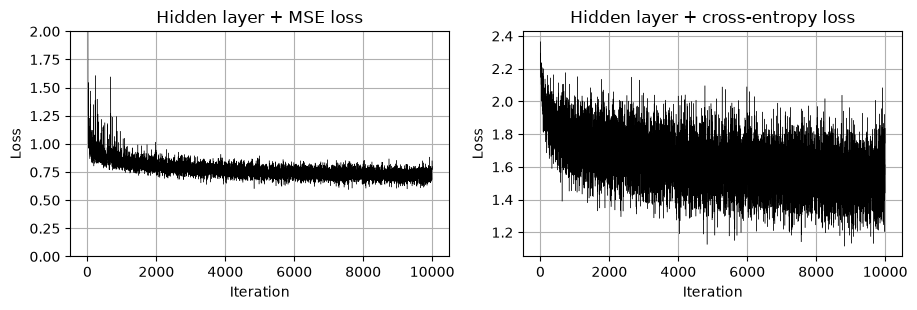

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9.3, 3.2))
curves = [(loss_history_mse, 'Hidden layer + MSE loss'),
          (loss_history_ce, 'Hidden layer + cross-entropy loss')]
for ax, (hist, title) in zip(axes, curves):
    ax.plot(hist, color='k', linewidth=0.3)
    ax.set_title(title)
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Loss')
    ax.grid(True)
axes[0].set_ylim(0, 2)  # the first few MSE iterations are much larger
plt.tight_layout()
plt.show()

In [17]:
results = [('Single layer + MSE (20 epochs)', baseline_train_acc, baseline_test_acc),
           ('Hidden layer + MSE (10 epochs)', mse_train_acc, mse_test_acc),
           ('Hidden layer + cross-entropy (10 epochs)', ce_train_acc, ce_test_acc)]

print(f"{'Network':<42}{'Train acc':>11}{'Test acc':>11}")
for name, tr, te in results:
    print(f'{name:<42}{tr:>10.2f}%{te:>10.2f}%')

Network                                     Train acc   Test acc
Single layer + MSE (20 epochs)                 32.23%     32.43%
Hidden layer + MSE (10 epochs)                 47.71%     44.01%
Hidden layer + cross-entropy (10 epochs)       48.55%     45.94%


$\textbf{Discussion:}$ adding the 100-node sigmoid hidden layer gave the biggest improvement. With the same MSE loss, the
test accuracy rose from $32.43\%$ (single layer, 20 epochs) to $44.01\%$ in only 10 epochs. The single-layer network is a
linear classifier: it can only learn one template per class, and its training and test accuracies were almost equal
($32.23\%$ vs $32.43\%$), which shows it was limited by its capacity rather than by overfitting. The sigmoid hidden layer
lets the network learn non-linear combinations of pixels, so it fits the data much better.

Switching from MSE to cross-entropy, with every other setting unchanged, improved the test accuracy further to
$45.94\%$ (training $48.55\%$). I think this is because the cross-entropy gradient $(\mathbf{p} - \mathbf{y})/N$ keeps pushing
the score of the correct class up until it dominates through the softmax, whereas MSE forces all ten outputs towards
exact 0/1 targets and spends effort on the wrong classes' scores even when the prediction is already correct. The loss
curves also show this: the MSE run had a large spike in the first iterations before settling, while the cross-entropy loss
fell smoothly from the start. The gap between training and test accuracy also became smaller with cross-entropy
($2.6$ points vs $3.7$ points for MSE).

The cross-entropy loss was still decreasing at the end of the 10 epochs, so training for longer (or with a larger
learning rate) would likely raise the accuracy further. However, a fully connected network on raw pixels ignores the
spatial structure of the image, so it cannot get close to the accuracy of a convolutional network on CIFAR-10.